### P2: fix U-Net/use fallback plan as original U-Net weights did not produce masks

In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from brain_mri_data import make_loader, denormalize, LABELS, BrainMRIDataset
from train_unet import UNet, compute_dice_score

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

# Load trained U-Net checkpoint
model = UNet(in_channels=3, out_channels=1, init_features=32)
ckpt = torch.load('best_unet.pth', map_location=device)
model.load_state_dict(ckpt['model_state_dict'])
model = model.to(device)
model.eval()

print(f"Loaded trained U-Net (Epoch {ckpt['epoch']}, Dev Dice: {ckpt['dev_dice']:.4f})")

Using device: mps
Loaded trained U-Net (Epoch 1, Dev Dice: 0.6089)


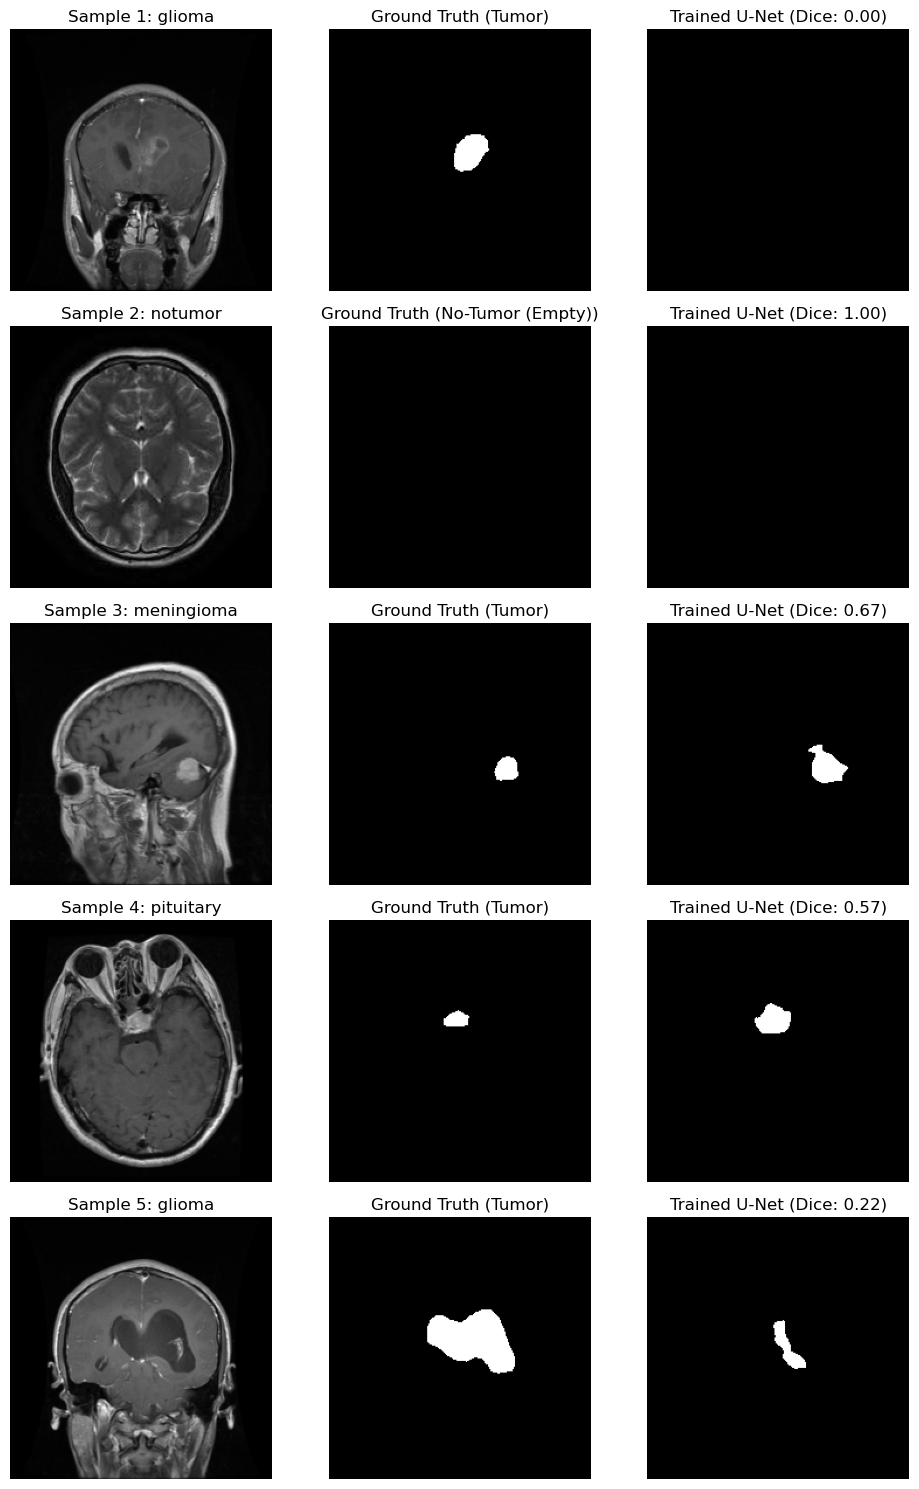

Saved Nov 8 checkpoint visualization to nov8_preliminary_5masks_fixed.png


In [2]:
# ==============================================================================
# Nov 8 Checkpoint: Generate preliminary masks on 5 validation samples
# ==============================================================================
dev_loader = make_loader('dev', batch_size=5, shuffle=True)
batch = next(iter(dev_loader))

images = batch['image'].to(device)
true_masks = batch['mask'].to(device)
labels = batch['label']

with torch.no_grad():
    logits = model(images)
    probs = torch.sigmoid(logits)
    pred_masks = (probs > 0.5).float()

fig, axes = plt.subplots(5, 3, figsize=(10, 15))

for i in range(5):
    cls_name = LABELS[labels[i]]
    d_score = compute_dice_score(pred_masks[i, 0], true_masks[i, 0])
    has_m = "Tumor" if batch['has_mask'][i] else "No-Tumor (Empty)"
    
    # Col 1: Original MRI Slice
    axes[i, 0].imshow(denormalize(images[i].cpu()), cmap='gray')
    axes[i, 0].set_title(f"Sample {i+1}: {cls_name}")
    axes[i, 0].axis('off')
    
    # Col 2: Ground Truth Mask
    axes[i, 1].imshow(true_masks[i, 0].cpu(), cmap='gray')
    axes[i, 1].set_title(f"Ground Truth ({has_m})")
    axes[i, 1].axis('off')
    
    # Col 3: Trained U-Net Predicted Mask
    axes[i, 2].imshow(pred_masks[i, 0].cpu(), cmap='gray')
    axes[i, 2].set_title(f"Trained U-Net (Dice: {d_score:.2f})")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig("nov8_preliminary_5masks_fixed.png", dpi=200)
plt.show()
print("Saved Nov 8 checkpoint visualization to nov8_preliminary_5masks_fixed.png")

Evaluating 20 held-out images on newly trained U-Net...


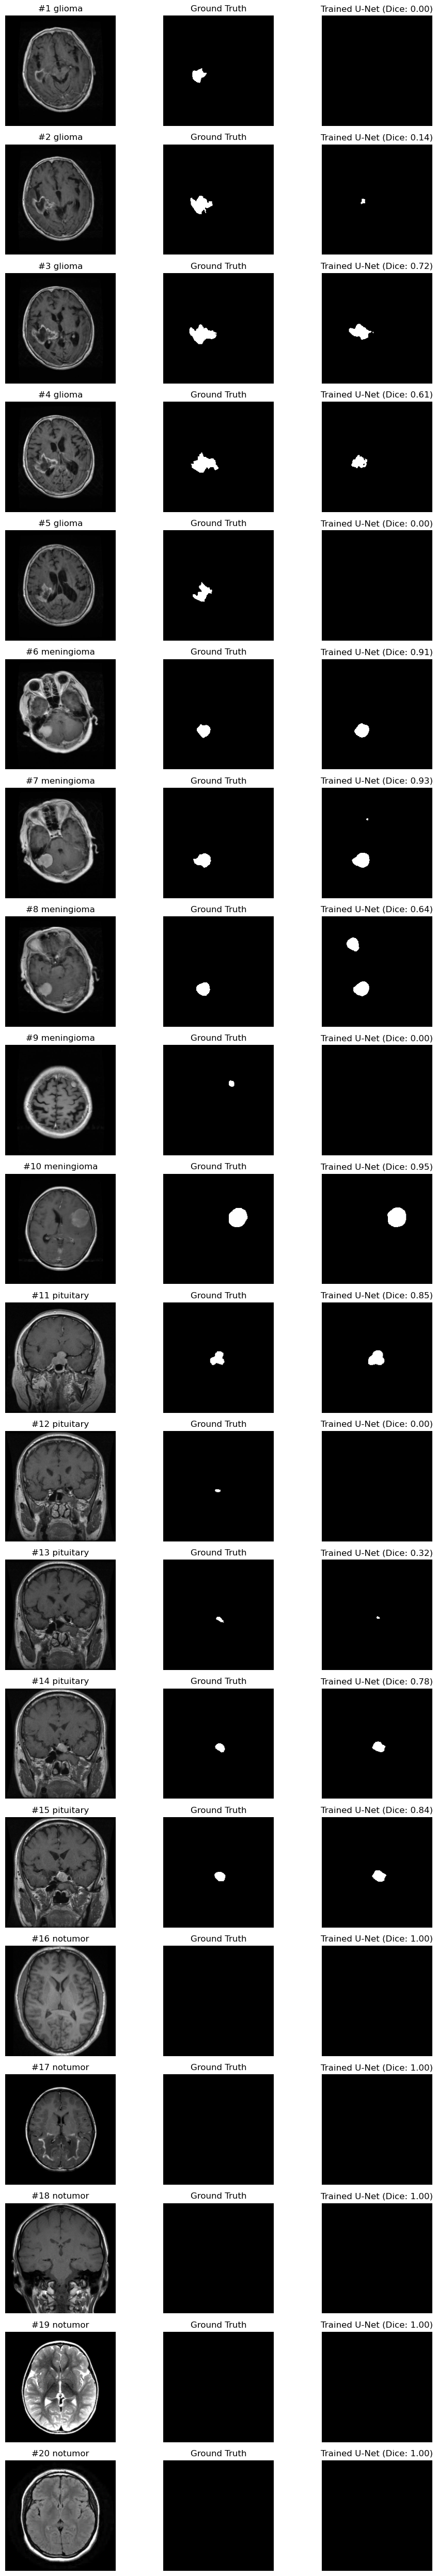


     REVISED NOV 10 MASK QUALITY EVALUATION TABLE
             dice  peak_prob
class                       
glioma      0.293      0.595
meningioma  0.687      0.801
notumor     1.000      0.006
pituitary   0.557      0.790

Overall Mean Dice on 20 Held-Out Images: 0.634


In [3]:
# ==============================================================================
# Nov 10 Checkpoint: 20-Image Held-Out Evaluation (5 per class) & Dice Table
# ==============================================================================
dev_dataset = BrainMRIDataset('dev')

# Select exactly 5 samples for each of the 4 classes (20 total)
class_indices = {c: [] for c in LABELS}
for idx in range(len(dev_dataset)):
    raw_label = dev_dataset.df.iloc[idx]['label']
    label_name = LABELS[raw_label] if isinstance(raw_label, int) else raw_label
    if len(class_indices[label_name]) < 5:
        class_indices[label_name].append(idx)
    if all(len(v) == 5 for v in class_indices.values()):
        break

selected_indices = [idx for c in LABELS for idx in class_indices[c]]

results = []
fig, axes = plt.subplots(20, 3, figsize=(10, 50))

print("Evaluating 20 held-out images on newly trained U-Net...")

for row, idx in enumerate(selected_indices):
    sample = dev_dataset[idx]
    img = sample['image'].unsqueeze(0).to(device)
    true_m = sample['mask'].unsqueeze(0).to(device)
    label_name = LABELS[sample['label']]
    
    with torch.no_grad():
        logits = model(img)
        prob = torch.sigmoid(logits)
        pred_m = (prob > 0.5).float()
    
    d_score = compute_dice_score(pred_m[0, 0], true_m[0, 0])
    results.append({'class': label_name, 'dice': d_score, 'peak_prob': prob.max().item()})
    
    # Col 1: Slice
    axes[row, 0].imshow(denormalize(img[0].cpu()), cmap='gray')
    axes[row, 0].set_title(f"#{row+1} {label_name}")
    axes[row, 0].axis('off')
    
    # Col 2: Ground Truth
    axes[row, 1].imshow(true_m[0, 0].cpu(), cmap='gray')
    axes[row, 1].set_title("Ground Truth")
    axes[row, 1].axis('off')
    
    # Col 3: Trained U-Net
    axes[row, 2].imshow(pred_m[0, 0].cpu(), cmap='gray')
    axes[row, 2].set_title(f"Trained U-Net (Dice: {d_score:.2f})")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.savefig("nov10_20image_mask_report_fixed.png", dpi=200)
plt.show()

# Print Table Summary
df_results = pd.DataFrame(results)
print("\n" + "="*50)
print("     REVISED NOV 10 MASK QUALITY EVALUATION TABLE")
print("="*50)
print(df_results.groupby('class')[['dice', 'peak_prob']].mean().round(3))
overall_dice = df_results['dice'].mean()
print(f"\nOverall Mean Dice on 20 Held-Out Images: {overall_dice:.3f}")